# 🚀 Devi · El asistente de DevSenior Code (entrenamiento largo, EXTRA)

**Clase 2 · Unidad 2** — notebook solo para el docente.

En clase entrenamos MiniGPT con **93 diálogos** durante unos minutos: aprendió el formato, pero sabe muy poco.
Aquí usamos **el mismo modelo (GPT-2 small en español) y el mismo formato de chat**, pero con **~52.000 instrucciones en español**, **la base de conocimiento de DevSenior Code y del Máster** y **hasta 2 horas de GPU**. El resultado es **Devi**, un mini chatbot de la empresa: una demo de cómo una compañía crea su propio asistente.

| | MiniGPT (clase) | **Devi (este notebook)** |
|---|---|---|
| Datos | 93 diálogos | ~52.000 instrucciones (Alpaca en español) + 93 diálogos + **base de conocimiento DevSenior** |
| Cómputo | minutos | hasta 2 horas en GPU |
| Lo que aprende | el formato de chat | seguir instrucciones variadas + **responder sobre la empresa y el Máster** + decir "no sé" en precios y fechas |

> **Expectativa realista:** sigue siendo un modelo de 124 M parámetros. Responderá mucho mejor y con más variedad, pero todavía inventará datos. Esa es la lección para la Clase 3: el tamaño del modelo y su preentrenamiento importan tanto como el fine-tuning.

**Dataset:** [`bertin-project/alpaca-spanish`](https://huggingface.co/datasets/bertin-project/alpaca-spanish): traducción al español de Stanford Alpaca (cc-by-4.0). Su ficha indica que no se puede usar para crear modelos que compitan con OpenAI: para uso educativo no hay problema.

▶️ **Cómo usarlo:** kernel con GPU (`minigpt`), revisa la configuración y ejecuta todo. Puedes dejarlo solo: guarda checkpoints y, si se interrumpe, vuelve a ejecutar todo y **retoma donde quedó**.

## 0. Configuración

In [1]:
import json, math, os, random, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, get_cosine_schedule_with_warmup

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 160)

# ---------------- CONFIGURACIÓN ----------------
MODELO_BASE = "datificate/gpt2-small-spanish"          # el mismo de la clase
DATASET_HF = "bertin-project/alpaca-spanish"           # ~52 mil instrucciones en español
RUTA_DIALOGOS = Path("..") / "datasets" / "dialogos_minigpt.jsonl"
NOMBRE_ASISTENTE = "Devi"                               # ← cámbialo y vuelve a entrenar
RUTA_EMPRESA = Path("..") / "datasets" / "devsenior_conocimiento.jsonl"
DIR_SALIDA = Path("..") / "modelo" / "devi-devsenior"  # modelo final (el mejor según validación)
DIR_CKPT = Path("..") / "modelo" / "_checkpoint_devi"  # para reanudar si se corta

HORAS_MAX = 2.0            # presupuesto de tiempo: se detiene al cumplirlo
EPOCHS_MAX = 6             # o al completar estas épocas (lo que pase primero)
LEARNING_RATE = 6e-5
BATCH_SIZE = 16
ACUMULAR = 2               # batch efectivo = 32
MAX_LEN = 256              # tokens por ejemplo
REPETIR_DIALOGOS = 10      # nuestros 93 diálogos ×10 (personalidad y conceptos de IA)
REPETIR_EMPRESA = 40       # base de conocimiento ×40: los datos de la empresa deben quedar "grabados"
EVAL_CADA = 400            # pasos de optimización entre evaluaciones
PACIENCIA = 6              # evaluaciones seguidas sin mejorar → early stopping
GUARDAR_CADA_MIN = 20      # checkpoint para reanudar
REANUDAR = True
SEED = 42

SYSTEM_PROMPT = (f"Eres {NOMBRE_ASISTENTE}, la asistente virtual de DevSenior Code. Respondes en español, "
                 "de forma breve y clara, sobre la academia, el Máster en IA y temas de inteligencia artificial.")
TAG_USUARIO, TAG_BOT = "### Usuario:", f"### {NOMBRE_ASISTENTE}:"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USAR_BF16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
print(f"torch {torch.__version__} | device: {device} | bfloat16: {USAR_BF16}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), f"| VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("⚠️ Sin GPU este notebook tardaría muchísimo. Úsalo en el entorno con CUDA.")

c:\Users\juand\anaconda3\envs\minigpt\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1018 15:21:25.541000 70204 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0+cu128 | device: cuda | bfloat16: True
GPU: NVIDIA GeForce RTX 4070 Laptop GPU | VRAM: 8.6 GB


## 1. Datos: Alpaca en español + nuestros diálogos + conocimiento de DevSenior
- **Alpaca** enseña a seguir instrucciones en general.
- **Nuestros 93 diálogos** aportan la personalidad y conceptos de IA (cambiamos "MiniGPT" por el nombre del asistente).
- **`devsenior_conocimiento.jsonl`**: 70 temas y 162 preguntas sobre la empresa y el Máster, escritas a partir de [devseniorcode.com](https://www.devseniorcode.com/) y del PDF oficial del Máster en IA. Cada tema tiene **varias formas de preguntarlo** y se repite muchas veces para que el modelo lo memorice. Incluye respuestas de **"no tengo esa información"** para precios, fechas y horarios, así el asistente remite a los canales oficiales en vez de inventar.

In [2]:
alpaca = load_dataset(DATASET_HF, split="train")
print(alpaca)

def a_pregunta(fila):
    instr, extra = fila["instruction"].strip(), (fila.get("input") or "").strip()
    return f"{instr}\n{extra}" if extra else instr

ejemplos = [{"pregunta": a_pregunta(f), "respuesta": f["output"].strip(), "origen": "alpaca"}
            for f in alpaca if f["output"].strip()]
dialogos = pd.read_json(RUTA_DIALOGOS, lines=True)
renombrar = lambda t: t.replace("MiniGPT", NOMBRE_ASISTENTE)

empresa = pd.read_json(RUTA_EMPRESA, lines=True)
empresa["respuesta"] = empresa["respuesta"].str.replace("{NOMBRE}", NOMBRE_ASISTENTE, regex=False)
print(f"Base de conocimiento: {empresa['id'].nunique()} temas, {len(empresa)} formas de preguntar")

# Variantes automáticas: la misma pregunta sin signos y en minúsculas ("que es devsenior code")
sin_signos = empresa.assign(pregunta=empresa.pregunta.str.replace("¿", "").str.replace("?", "").str.lower())
empresa_total = pd.concat([empresa, sin_signos]).drop_duplicates(subset=["pregunta"])
ejemplos += [{"pregunta": p, "respuesta": r, "origen": "devsenior"}
             for p, r in zip(empresa_total.pregunta, empresa_total.respuesta)] * REPETIR_EMPRESA

# Diálogos de clase: quitamos los que repiten una pregunta de la empresa (evita respuestas contradictorias)
preguntas_empresa = set(empresa.pregunta.str.lower())
dialogos = dialogos[~dialogos.pregunta.str.lower().isin(preguntas_empresa)]
ejemplos += [{"pregunta": renombrar(p), "respuesta": renombrar(r), "origen": "dialogos"}
             for p, r in zip(dialogos.pregunta, dialogos.respuesta)] * REPETIR_DIALOGOS

df = pd.DataFrame(ejemplos).sample(frac=1, random_state=SEED).reset_index(drop=True)
n_val = min(1500, int(len(df) * 0.03))
df_val, df_train = df.iloc[:n_val], df.iloc[n_val:]
print(f"Total: {len(df):,} | train: {len(df_train):,} | validación: {len(df_val):,}")
print(df_train.origen.value_counts().to_dict())
df_train.head(5)

Dataset({
    features: ['instruction', 'input', 'output'],
    num_rows: 51942
})
Base de conocimiento: 70 temas, 162 formas de preguntar
Total: 65,682 | train: 64,182 | validación: 1,500
{'alpaca': 50746, 'devsenior': 12669, 'dialogos': 767}


,pregunta,respuesta,origen
1500,Selecciona la palabra más cercana a la definición dada.\nDefinición: sin disminución de valor\nOpciones:\n(A) garantizado\n(B) persistente\n(C) vigoroso\n(D...,D,alpaca
1501,Convertir 2lbs a kilogramos.,2lbs es igual a 0.90719 kilogramos.,alpaca
1502,¿Cómo está relacionado el concepto de sostenibilidad con el cambio climático global?,"La sostenibilidad está estrechamente relacionada con el cambio climático global, ya que abarca los esfuerzos para reducir las emisiones de gases de efecto i...",alpaca
1503,Nombre una nueva tecnología relevante que podría ser utilizada para mejorar la atención médica.,"Una tecnología relevante que podría ser utilizada para mejorar la atención médica es el uso de la inteligencia artificial (IA), la cual puede ayudar a autom...",alpaca
1504,Normalice los siguientes números de seguimiento de UPS.\nX1Y54ZF445,X1Y54ZF445 → X1Y54ZF4453,alpaca


## 2. Tokenizar (labels = −100 en el prompt, igual que en clase)

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def construir_prompt(pregunta):
    return f"{SYSTEM_PROMPT}\n\n{TAG_USUARIO} {pregunta}\n{TAG_BOT}"

def codificar(pregunta, respuesta):
    ids_p = tokenizer.encode(construir_prompt(pregunta))
    ids_r = tokenizer.encode(" " + respuesta) + [tokenizer.eos_token_id]
    ids = (ids_p + ids_r)[:MAX_LEN]
    labels = ([-100] * len(ids_p) + ids_r)[:MAX_LEN]
    return ids, labels

inicio = time.time()
datos_train = [codificar(p, r) for p, r in zip(df_train.pregunta, df_train.respuesta)]
datos_val = [codificar(p, r) for p, r in zip(df_val.pregunta, df_val.respuesta)]
# Descartamos ejemplos cuyo prompt ya ocupa todo MAX_LEN (no queda respuesta que aprender)
datos_train = [d for d in datos_train if any(l != -100 for l in d[1])]
datos_val = [d for d in datos_val if any(l != -100 for l in d[1])]
largos = np.array([len(d[0]) for d in datos_train])
print(f"Tokenizado en {time.time() - inicio:.0f}s | train {len(datos_train):,} | val {len(datos_val):,}")
print(f"Tokens por ejemplo: media {largos.mean():.0f}, p95 {np.percentile(largos, 95):.0f}, total {largos.sum() / 1e6:.1f} M por época")

Tokenizado en 30s | train 64,147 | val 1,499
Tokens por ejemplo: media 127, p95 239, total 8.1 M por época


## 3. Batches eficientes
Agrupamos ejemplos de **largo parecido** en cada batch: así casi no hay padding y la GPU no gasta tiempo en relleno. El orden depende de la época (semilla), por eso podemos **reanudar** exactamente donde quedamos.

In [4]:
def batches_de_epoca(datos, epoca, batch_size=BATCH_SIZE):
    rng = random.Random(SEED + epoca)
    idx = list(range(len(datos))); rng.shuffle(idx)
    grupos = [idx[i:i + batch_size * 50] for i in range(0, len(idx), batch_size * 50)]
    lotes = []
    for g in grupos:
        g = sorted(g, key=lambda i: len(datos[i][0]))
        lotes += [g[i:i + batch_size] for i in range(0, len(g), batch_size)]
    rng.shuffle(lotes)
    return lotes

def collate(datos, indices):
    largo = max(len(datos[i][0]) for i in indices)
    ids = torch.full((len(indices), largo), tokenizer.pad_token_id)
    labels = torch.full((len(indices), largo), -100)
    mask = torch.zeros((len(indices), largo), dtype=torch.long)
    for k, i in enumerate(indices):
        a, b = datos[i]
        ids[k, :len(a)] = torch.tensor(a); labels[k, :len(b)] = torch.tensor(b); mask[k, :len(a)] = 1
    return {"input_ids": ids.to(device), "attention_mask": mask.to(device), "labels": labels.to(device)}

pasos_por_epoca = math.ceil(len(batches_de_epoca(datos_train, 0)) / ACUMULAR)
print(f"Pasos de optimización por época: {pasos_por_epoca:,}")

Pasos de optimización por época: 2,005


## 4. Modelo, optimizador y (si existe) checkpoint para reanudar

In [5]:
modelo = AutoModelForCausalLM.from_pretrained(MODELO_BASE).to(device)
optimizador = torch.optim.AdamW(modelo.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
pasos_totales = pasos_por_epoca * EPOCHS_MAX
scheduler = get_cosine_schedule_with_warmup(optimizador, num_warmup_steps=min(500, pasos_totales // 20),
                                            num_training_steps=pasos_totales)
estado = {"epoca": 0, "lote_en_epoca": 0, "paso": 0, "mejor_val": float("inf"), "sin_mejorar": 0,
          "segundos": 0.0, "hist_train": [], "hist_val": []}

archivo_ckpt = DIR_CKPT / "estado.pt"
if REANUDAR and archivo_ckpt.exists():
    ck = torch.load(archivo_ckpt, map_location=device, weights_only=False)
    modelo.load_state_dict(ck["modelo"]); optimizador.load_state_dict(ck["optimizador"])
    scheduler.load_state_dict(ck["scheduler"]); estado = ck["estado"]
    print(f"🔁 Reanudando: época {estado['epoca']}, paso {estado['paso']:,}, "
          f"{estado['segundos'] / 60:.0f} min ya entrenados, mejor val {estado['mejor_val']:.3f}")
else:
    print("🆕 Entrenamiento desde el modelo base.")
print(f"Parámetros: {sum(p.numel() for p in modelo.parameters()) / 1e6:.0f} M")

Loading weights: 100%|██████████| 149/149 [00:00<00:00, 22813.44it/s]


🆕 Entrenamiento desde el modelo base.
Parámetros: 124 M


In [6]:
@torch.no_grad()
def evaluar(max_lotes=60):
    modelo.eval()
    lotes = batches_de_epoca(datos_val, 999)[:max_lotes]
    total, n = 0.0, 0
    for idx in lotes:
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USAR_BF16):
            total += modelo(**collate(datos_val, idx)).loss.item(); n += 1
    modelo.train()
    return total / max(n, 1)

def guardar_checkpoint():
    DIR_CKPT.mkdir(parents=True, exist_ok=True)
    torch.save({"modelo": modelo.state_dict(), "optimizador": optimizador.state_dict(),
                "scheduler": scheduler.state_dict(), "estado": estado}, archivo_ckpt)

def guardar_mejor():
    DIR_SALIDA.mkdir(parents=True, exist_ok=True)
    modelo.save_pretrained(DIR_SALIDA); tokenizer.save_pretrained(DIR_SALIDA)

## 5. Entrenamiento largo
Se detiene por lo primero que ocurra: **HORAS_MAX**, **EPOCHS_MAX** o **early stopping** (la validación deja de mejorar). Cada vez que mejora la validación se guarda el modelo en `DIR_SALIDA` ⭐.

In [7]:
if estado["paso"] == 0 and not DIR_SALIDA.exists():
    estado["hist_val"].append((0, evaluar())); print(f"Validación inicial: {estado['hist_val'][-1][1]:.3f}")

modelo.train()
limite = HORAS_MAX * 3600
t0, ult_ckpt = time.time() - estado["segundos"], time.time()
tokens_vistos, t_vel, motivo = 0, time.time(), "EPOCHS_MAX completadas"
acum_loss, acum_n = 0.0, 0

for epoca in range(estado["epoca"], EPOCHS_MAX):
    lotes = batches_de_epoca(datos_train, epoca)
    for j in range(estado["lote_en_epoca"], len(lotes)):
        lote = collate(datos_train, lotes[j])
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USAR_BF16):
            perdida = modelo(**lote).loss / ACUMULAR
        perdida.backward()
        acum_loss += perdida.item() * ACUMULAR; acum_n += 1
        tokens_vistos += int(lote["attention_mask"].sum())
        estado["lote_en_epoca"] = j + 1

        if (j + 1) % ACUMULAR == 0 or j + 1 == len(lotes):
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step(); scheduler.step(); optimizador.zero_grad(set_to_none=True)
            estado["paso"] += 1

            if estado["paso"] % 50 == 0:
                estado["hist_train"].append((estado["paso"], acum_loss / acum_n)); acum_loss, acum_n = 0.0, 0

            if estado["paso"] % EVAL_CADA == 0:
                v = evaluar(); estado["hist_val"].append((estado["paso"], v))
                vel = tokens_vistos / (time.time() - t_vel); tokens_vistos, t_vel = 0, time.time()
                transcurrido = time.time() - t0
                marca = ""
                if v < estado["mejor_val"]:
                    estado["mejor_val"], estado["sin_mejorar"] = v, 0; guardar_mejor(); marca = " ⭐ guardado"
                else:
                    estado["sin_mejorar"] += 1
                print(f"época {epoca + 1}/{EPOCHS_MAX} · paso {estado['paso']:,} · train "
                      f"{estado['hist_train'][-1][1] if estado['hist_train'] else float('nan'):.3f} · val {v:.3f} · "
                      f"{vel:,.0f} tokens/s · {transcurrido / 60:.0f}/{HORAS_MAX * 60:.0f} min{marca}")

            estado["segundos"] = time.time() - t0
            if time.time() - ult_ckpt > GUARDAR_CADA_MIN * 60:
                guardar_checkpoint(); ult_ckpt = time.time()
            if estado["segundos"] >= limite:
                motivo = f"se cumplieron {HORAS_MAX} h"; break
            if estado["sin_mejorar"] >= PACIENCIA:
                motivo = "early stopping (la validación dejó de mejorar)"; break
    else:
        estado["epoca"], estado["lote_en_epoca"] = epoca + 1, 0
        continue
    break

if not (DIR_SALIDA / "config.json").exists():          # por si terminó antes de la primera evaluación
    estado["mejor_val"] = evaluar(); guardar_mejor()
guardar_checkpoint()
print(f"\n⏹️ Fin: {motivo} · {estado['segundos'] / 60:.0f} min · {estado['paso']:,} pasos · mejor val {estado['mejor_val']:.3f}")

Validación inicial: 4.041


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.16it/s]


época 1/6 · paso 400 · train 2.468 · val 2.262 · 5,079 tokens/s · 5/120 min ⭐ guardado


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.10it/s]


época 1/6 · paso 800 · train 2.128 · val 1.927 · 5,636 tokens/s · 10/120 min ⭐ guardado


...

época 3/6 · paso 6,000 · train 1.393 · val 1.579 · 2,207 tokens/s · 97/120 min ⭐ guardado
época 4/6 · paso 6,400 · train 1.275 · val 1.586 · 4,386 tokens/s · 103/120 min


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.19it/s]


época 4/6 · paso 6,800 · train 1.387 · val 1.579 · 4,245 tokens/s · 110/120 min ⭐ guardado


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.42it/s]


época 4/6 · paso 7,200 · train 1.381 · val 1.574 · 4,517 tokens/s · 116/120 min ⭐ guardado

⏹️ Fin: se cumplieron 2.0 h · 120 min · 7,490 pasos · mejor val 1.574


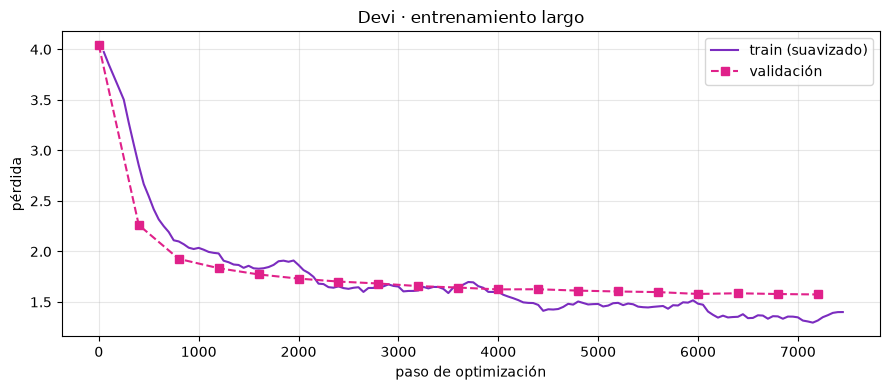

{'asistente': 'Devi',
 'modelo_base': 'datificate/gpt2-small-spanish',
 'dataset': 'bertin-project/alpaca-spanish',
 'ejemplos_train': 64147,
 'minutos': 120.0,
 'pasos': 7490,
 'mejor_val': 1.5744}

In [8]:
# Curvas de pérdida
fig, ax = plt.subplots(figsize=(9, 4))
if estado["hist_train"]:
    x, y = zip(*estado["hist_train"]); ax.plot(x, pd.Series(y).rolling(5, min_periods=1).mean(), color="#7B2CBF", label="train (suavizado)")
if estado["hist_val"]:
    x, y = zip(*estado["hist_val"]); ax.plot(x, y, "s--", color="#E0218A", label="validación")
ax.set_xlabel("paso de optimización"); ax.set_ylabel("pérdida"); ax.set_title(f"{NOMBRE_ASISTENTE} · entrenamiento largo")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

info = {"asistente": NOMBRE_ASISTENTE, "modelo_base": MODELO_BASE, "dataset": DATASET_HF, "ejemplos_train": len(datos_train),
        "minutos": round(estado["segundos"] / 60, 1), "pasos": estado["paso"], "mejor_val": round(estado["mejor_val"], 4)}
DIR_SALIDA.mkdir(parents=True, exist_ok=True)
json.dump(info, open(DIR_SALIDA / "info_entrenamiento.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
info

## 6. Probemos a Devi: MiniGPT (clase) vs asistente de la empresa
Cargamos **el mejor** modelo guardado y, si existe, el MiniGPT de la clase (`../modelo/miniGPT-es`).
Ojo: el MiniGPT de clase usa su propio formato (`### MiniGPT:`), por eso lo llamamos con su prompt original.

In [9]:
from transformers import StoppingCriteria, StoppingCriteriaList

class PararEnTag(StoppingCriteria):
    def __init__(self, tok, tag, n): self.tok, self.tag, self.n = tok, tag, n
    def __call__(self, input_ids, scores, **kw):
        return torch.full((input_ids.shape[0],), self.tag in self.tok.decode(input_ids[0, self.n:]),
                          dtype=torch.bool, device=input_ids.device)

def responder(m, tok, pregunta, max_new_tokens=120, muestrear=False, prompt=None):
    ent = tok(prompt or construir_prompt(pregunta), return_tensors="pt").to(device); n = ent["input_ids"].shape[1]
    op = dict(do_sample=True, temperature=0.7, top_p=0.9) if muestrear else dict(do_sample=False)
    with torch.no_grad():
        out = m.generate(**ent, max_new_tokens=max_new_tokens, no_repeat_ngram_size=3, **op,
                         pad_token_id=tok.eos_token_id, eos_token_id=tok.eos_token_id,
                         stopping_criteria=StoppingCriteriaList([PararEnTag(tok, "###", n)]))
    return tok.decode(out[0, n:], skip_special_tokens=True).split("###")[0].strip()

pro = AutoModelForCausalLM.from_pretrained(DIR_SALIDA).to(device).eval()
tok_pro = AutoTokenizer.from_pretrained(DIR_SALIDA)
ruta_clase = Path("..") / "modelo" / "miniGPT-es"
clase = AutoModelForCausalLM.from_pretrained(ruta_clase).to(device).eval() if ruta_clase.exists() else None
tok_clase = AutoTokenizer.from_pretrained(ruta_clase) if clase is not None else None

prompt_clase = lambda p: ("Eres MiniGPT, un asistente que responde en español de forma breve y clara.\n\n"
                          f"### Usuario: {p}\n### MiniGPT:")
preguntas = {
    "empresa (en el dataset)": ["¿Qué es DevSenior Code?", "¿Cuántos módulos tiene el máster?", "¿Cuál es el correo de DevSenior?"],
    "empresa (redactadas distinto)": ["oye, ¿cómo me comunico con ustedes?", "Cuéntame del máster de IA",
                                      "¿En el programa enseñan Docker?", "¿Qué hago en el proyecto final?"],
    "debe decir que no sabe": ["¿Cuánto cuesta el máster?", "¿Cuándo empiezan las clases?"],
    "generales (Alpaca)": ["Dame tres consejos para dormir mejor.", "Escribe un poema corto sobre el mar.",
                           "Explica qué es la fotosíntesis en dos frases."],
}
filas = []
for tipo, lista in preguntas.items():
    for p in lista:
        filas.append({"tipo": tipo, "pregunta": p,
                      "MiniGPT (clase)": responder(clase, tok_clase, p, prompt=prompt_clase(p)) if clase is not None else "—",
                      NOMBRE_ASISTENTE: responder(pro, tok_pro, p)})
pd.DataFrame(filas)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 305.51it/s]


,tipo,pregunta,MiniGPT (clase),Devi
0,empresa (en el dataset),¿Qué es DevSenior Code?,"Es un modelo de lenguaje de programación que permite a los programadores aprender a programar con lenguaje natural. Somerhant, un modelo más pequeño, permit...","DevSenario Code es una academia de formación tecnológica que forma desarrolladores y AI Engineers con mentores senior activos en producción, proyectos reale..."
1,empresa (en el dataset),¿Cuántos módulos tiene el máster?,"No tengo el máster, pero tengo un módulo que aprendes a leer y escribir. dígales como el de la IA, el de las redes neuronales, el del lenguaje humano, el le...","Tiene 3 módulos: 1) Fundamentos de IA, Ciencia de Datos y Machine Learning; 2) Desarrollador Full Stack de Soluciones Inteligentes; 3) Científico de Datos e..."
2,empresa (en el dataset),¿Cuál es el correo de DevSenior?,Es el correo que hace el modelo de redes neuronales más fácil de aprender. Medinacelli dijo que el modelo es el método más usado para aprender redes neurona...,Puedes escribir a hola@devseniorcode.com. Para empresas y la academia también está academy@devSeniorcodea.com
3,empresa (redactadas distinto),"oye, ¿cómo me comunico con ustedes?","No. Soy MiniGPt. Soy un modelo de lenguaje natural: aprende a predecir, a predecir y a aprender.trepo a los estudiantes a partir de datos de texto.trepo tam...","Puedes escribir por WhatsApp o llamar al +1 786 798 7108, o enviar un correo a hola@devseniorcode.com."
4,empresa (redactadas distinto),Cuéntame del máster de IA,¡Qué! Es una librería de Python para aprender y entrenar a los estudiantes de IA. Prepara a los alumnos a través de una clase. dígale el modelo de aprendiza...,"Es el Máster de Inteligencia Artificial & Data Science: Construyendo Soluciones Inteligentes. Va desde Python y análisis de datos hasta machine learning, re..."
5,empresa (redactadas distinto),¿En el programa enseñan Docker?,"No. Soy un modelo de lenguaje: un modelo es un conjunto de datos que se usa para entrenar o evaluar un modelo.trepo a un modelo, el modelo aprende cómo apre...",Sí. El programa es en Python y se puede utilizar para aprender embeddings y otras tecnologías de programación.
6,empresa (redactadas distinto),¿Qué hago en el proyecto final?,"Es el siguiente paso: cada token debe responder con un valor de verdad, por ejemplo, un valor que indica cuánto tiempo ha tardado en responder. Culiated le ...","El proyecto final tiene 4 módulos: 1) Fundamentos de IA, Ciencia de Datos y Machine Learning; 2) Desarrollador Full Stack de Soluciones Inteligentes; 3) Cie..."
7,debe decir que no sabe,¿Cuánto cuesta el máster?,No. Solo cuesta el doctorado si tienes un trabajo que aprendes a leer y escribir.dóñez es el campo de la IA que usa la IA para aprender a entender.dóñez usa...,No tengo los precios actualizados. Un asesor te los da según tu país y las opciones de financiamiento: escribe por WhatsApp al +1 786 798 7108.
8,debe decir que no sabe,¿Cuándo empiezan las clases?,Primero aprendes a usar texto y luego aprendes cómo usar texto. dígers que aprendes texto a partir de texto básico. díger que aprendo a usar textos básicos ...,"Las clases empiezan con un discurso y un proyecto final. La clase es un reto real en NLP, visión por computador, sistemas de recomendación o modelos predict..."
9,generales (Alpaca),Dame tres consejos para dormir mejor.,¿Por qué no puedo dormir mejor que con otras personas? Porque tengo que trabajar con otras gente.trepo un libro sobre esto.trepo una novela sobre esto y lue...,1. Duerme lo suficiente y duerme lo suficiente.\n2. Haz ejercicio regularmente y practique yoga.\n3. Haz una lista diaria de actividades que te ayuden a man...


### ¿Cuánto memorizó de la empresa?
Para cada uno de los 70 temas hacemos la **primera pregunta** del dataset y medimos qué porcentaje de las palabras de la respuesta oficial aparecen en la respuesta del asistente. Es una métrica simple (no entiende sinónimos), pero sirve para ver el avance.

In [10]:
import re
palabras = lambda t: set(re.findall(r"\w+", t.lower()))
filas = []
for tema, grupo in empresa.groupby("id"):
    p, oficial = grupo.iloc[0].pregunta, grupo.iloc[0].respuesta
    r = responder(pro, tok_pro, p)
    cobertura = len(palabras(oficial) & palabras(r)) / max(1, len(palabras(oficial)))
    filas.append({"pregunta": p, "cobertura": round(cobertura, 2), "respuesta": r})
memoria = pd.DataFrame(filas).sort_values("cobertura")
print(f"Temas con ≥ 70 % de cobertura: {(memoria.cobertura >= .7).mean():.0%} · cobertura media: {memoria.cobertura.mean():.0%}")
memoria.head(10)          # los peores primero: ahí conviene agregar más formas de preguntar

Temas con ≥ 70 % de cobertura: 94% · cobertura media: 97%


,pregunta,cobertura,respuesta
3,¿Eres una persona?,0.26,"No, soy Devi. Soy Devi de India, y te formamos para entender tu código."
49,¿Cuál es el horario de atención?,0.61,"De lunes a viernes: 8:00 a.m. a 6:00 p.m., 7:00 al.m."" a 5:00 PM.\nAhorros: 8 de agosto a 6 de agosto.\nViernes: 8 a. m. a 5 de agosto\nDomingo: 8 p. m., 6 ..."
0,¿Cómo te llamas?,0.65,"Soy Devi. Soy Deví, la asistentes virtual dedevseniorcode.com. Puedo contarte sobre la empresa, sus carreras y el Máster."
68,Hola,0.67,¡Hola! Soy Devi y la asistente de Devsenior Code: soy un placer conocerte.
1,¿Qué puedes hacer?,0.90,"Respondo preguntas sobre DevSenario Code: carreras, programas, másters, metodología, certificaciones, apoyo laboral, financiamiento y el Máster de Inteligen..."
67,Gracias,0.91,"¡Con gusto! Si tienes más preguntas sobre DevSenario Code, aquí estoy."
46,¿Hacen desarrollo de software?,0.94,"Sí. Además de formar, DevSenar construye software a la medida: plataformas, portales, integración de IA y automatización de procesos."
52,¿Qué es el Máster en Inteligencia Artificial?,0.94,"Es el Máster En Inteligencia Artilica: Construyendo Soluciones Inteligentes. Va desde Python y análisis de datos hasta machine learning, redes neuronales, N..."
13,¿Cuántos estudiantes tiene DevSenior Code?,0.94,"Más de 1.500 desarrolladores se están formando con DevSenario Code, en Latinoamérica, España y Estados Unidos."
2,¿Quién te creó?,0.96,Me entrenaron en la clase de Transformers del Máster en Inteligencia Artificial de Devsenior Code: soy un GPT-2 en español ajustado con instrucciones y con ...


In [11]:
# Chat con el asistente (escribe 'salir' para terminar). Para datos de la empresa usa muestrear=False.
def chatear(muestrear=False):
    while True:
        p = input("🧑 Tú: ").strip()
        if p.lower() in {"salir", ""}: break
        print(f"🤖 {NOMBRE_ASISTENTE}:", responder(pro, tok_pro, p, muestrear=muestrear), "\n")

# chatear()

## 🧑‍🏫 Cómo usar este resultado en clase
- **La gran lección: fine-tuning vs RAG.** Devi "memorizó" los datos de la empresa entrenando. Funciona para una demo, pero si cambia un dato (teléfono, temario) hay que **volver a entrenar**, y un modelo pequeño puede mezclar datos. Las empresas reales suelen usar **RAG**: el asistente busca la información en documentos actualizados y la pone en el prompt (Unidad 3). Pregunta al grupo: *¿qué pasa si mañana cambia el correo de contacto?*
- **Prueba en vivo:** que los estudiantes le pregunten cosas del Máster con sus propias palabras. Las que más se alejan de las frases del dataset son las que más fallan.
- **Antes vs después:** proyecta la tabla de la sección 6. Mismo modelo, mismo código; la diferencia es **datos + cómputo**.
- **Pregunta para el grupo:** "¿Por qué Devi sigue inventando cosas en temas generales?" → 124 M parámetros y un preentrenamiento pequeño. Un LLM como Qwen3 (Clase 3) tiene 5 veces más parámetros y fue preentrenado con billones de tokens.
- **En la Clase 3** puedes compararlo con Qwen3 cambiando `RUTA_MINIGPT` a `.../modelo/devi-devsenior`.
- **Escala real:** ChatGPT se ajustó con muchísimas más instrucciones y además con RLHF; aquí hicimos la versión casera de ese SFT.
- La carpeta `_checkpoint_devi` (~1,5 GB, incluye el estado del optimizador) puede borrarse cuando estés conforme con el modelo.